In [ ]:
# Path setup: lets the notebook run from anywhere inside the repo
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and (p / "src").is_dir())
DATA = ROOT / "data"
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "supervisor_code")]

In [ ]:
import importlib
import functions_jules
importlib.reload(functions_jules)

from functions_jules import * 


In [11]:
#Specific for LASSO

from sklearn.linear_model import lasso_path
from sklearn.preprocessing import StandardScaler
from tqdm import tqdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# 🧪 Étude du LASSO dans un modèle ARCH-X et plan pour le modèle MS-ARCH-X

---

## ✅ Ce qui est fait

1. **Objectif initial** : tester la capacité du LASSO à identifier les bonnes variables exogènes dans un modèle de volatilité simulé.

2. **Méthodologie :**
   - Génération de 10 variables exogènes AR(1), dont **2 uniquement** influencent la volatilité conditionnelle.
   - Simulation d’un modèle **ARCH(1)-X** :
     \[
     \sigma_t^2 = \omega + \alpha r_{t-1}^2 + \sum_{j=1}^{10} \gamma_j X_{j,t}
     \]
     avec \(\gamma_j = 0\) sauf pour 2 variables.
   - Simulation des rendements \(r_t \sim \mathcal{N}(0, \sigma_t^2)\)
   - Application de `lasso_path` (sklearn) pour balayer différentes valeurs de \(\lambda\) et identifier les deux variables les plus pertinentes.
   - Répétition de cette expérience sur plusieurs essais pour calculer un **taux de réussite**.

---

## 🧠 Compréhensions

### ❌ Limites de la méthode actuelle (LASSO + ARCH-X)

- `lasso_path` ne s’applique **que dans un cadre de régression linéaire** — il est adapté à ARCH-X mais **pas** à MS-ARCH-X, qui est un modèle **non-linéaire avec états cachés**.

- Il est **interdit de figer des coefficients à 0** (faire de la sélection de variables) en se basant sur :
  - Une estimation Viterbi faite **sans exogènes** produit une classification biaisée :
    - Le chemin \(S_t\) estimé par Viterbi repose sur un modèle **réduit**, où les variables exogènes sont absentes.
    - Or, si les exogènes influencent réellement la volatilité ou la dynamique des régimes, leur absence fausse l’estimation de la probabilité des états cachés.
    - Résultat : les observations sont **mal classées entre régimes**, ce qui induit une **mauvaise séparation des données** si on applique ensuite un LASSO dans chaque régime.
    - Une variable utile pourrait apparaître "inutile" simplement parce qu’elle agit dans un régime mal détecté.

  - Une estimation partielle (sous-modèle) — cela compromettrait toute la validité théorique.

- En revanche, on **peut utiliser LASSO pour proposer des conditions initiales**, **à condition** de laisser tous les coefficients libres ensuite pendant l'estimation complète.

---



0	Imported packages and set reproducibility
1	Defined experimental parameters and true active variables
2	Simulated AR(1) exogenous variables
3	Simulated returns using ARCH-X model
4	Built LASSO-compatible design matrix
5	Used lasso_path to find λ selecting exactly 2 exogenous variables
6	Evaluated whether the correct variables were selected
Opt.	Visualized the coefficient paths

In [2]:

def single_lasso_trial(T=5000, k=10, true_nonzero_idxs=[2, 6], gamma_vals=[0.8, 0.5], 
                       phi=0.8, omega=0.1, alpha=0.2, random_seed=None):
    """
    Run one simulation and LASSO trial on an ARCH-X model.
    
    Parameters:
    - T (int): Number of time steps.
    - k (int): Total number of exogenous variables.
    - true_nonzero_idxs (list): Indices of exogenous variables that actually affect volatility.
    - gamma_vals (list): Coefficients for the true active exogenous variables.
    - phi (float): AR(1) parameter for exogenous variables.
    - omega, alpha (float): ARCH parameters.
    - random_seed (int): Random seed for reproducibility.
    
    Returns:
    - dict containing selected variables, true variables, success flag, coefficients, and lambda.
    """
    if random_seed is not None:
        np.random.seed(random_seed)
    
    # Step 1: Define true gamma vector
    gamma_values = np.zeros(k)
    gamma_values[true_nonzero_idxs[0]] = gamma_vals[0]
    gamma_values[true_nonzero_idxs[1]] = gamma_vals[1]

    # Step 2: Simulate AR(1) exogenous variables
    X = np.zeros((T, k))
    for j in range(k):
        for t in range(1, T):
            X[t, j] = phi * X[t - 1, j] + np.random.normal(0, 1)

    # Step 3: Generate ARCH-X returns
    sigma_squared = np.zeros(T)
    returns = np.zeros(T)
    returns[0] = 0
    
    for t in range(1, T):
        sigma_squared[t] = omega + alpha * returns[t - 1]**2 + np.dot(gamma_values, X[t, :])
        sigma_squared[t] = np.abs(sigma_squared[t])
        returns[t] = np.random.normal(0, np.sqrt(sigma_squared[t]))

    # Step 4: Standardize exogenous variables
    X_exo = X[1:, :]  # Drop first row to align with y_lasso
    scaler = StandardScaler()
    X_exo_scaled = scaler.fit_transform(X_exo)

    # Step 5: Build LASSO design matrix and target
    r_squared_lag = returns[:-1]**2
    X_lasso = np.column_stack([r_squared_lag, X_exo_scaled])
    y_lasso = sigma_squared[1:]

    # Step 6: Run LASSO path
    alphas, coefs, _ = lasso_path(X_lasso, y_lasso)
    exogenous_coefs = coefs[1:, :]  # Exclude r_squared_lag from selection

    selected_lambda, selected_variables = None, None
    for i in range(len(alphas)):
        nonzero_indices = np.where(exogenous_coefs[:, i] != 0)[0]
        if len(nonzero_indices) == 2:
            selected_lambda = alphas[i]
            selected_variables = nonzero_indices
            break

    success = set(selected_variables) == set(true_nonzero_idxs) if selected_variables is not None else False
    selected_coefs = (
        exogenous_coefs[:, np.where(alphas == selected_lambda)[0][0]][selected_variables]
        if selected_variables is not None else None
    )

    return {
        'selected_lambda': selected_lambda,
        'selected_variables': selected_variables,
        'selected_coefficients': selected_coefs,
        'true_active_variables': true_nonzero_idxs,
        'success': success
    }


In [5]:
result = single_lasso_trial(random_seed=76)

print("Lambda sélectionné :", result['selected_lambda'])
print("Variables choisies par LASSO :", result['selected_variables'])
print("Vrais indices actifs :", result['true_active_variables'])
print("Succès de la sélection :", "✅ Oui" if result['success'] else "❌ Non")
print("Coefficients des variables choisies :", result['selected_coefficients'])


Lambda sélectionné : 0.10098545319960076
Variables choisies par LASSO : [2 6]
Vrais indices actifs : [2, 6]
Succès de la sélection : ✅ Oui
Coefficients des variables choisies : [0.13293584 0.00331017]


In [ ]:
num_trials = 2000
results = []

for trial in range(num_trials):
    result = single_lasso_trial(T=5000, k=10, true_nonzero_idxs=[2, 6], gamma_vals=[0.8, 0.5], 
                       phi=0.8, omega=0.1, alpha=0.2, random_seed=None)
    results.append(result)

# Creating a DataFrame for easy analysis
df_results = pd.DataFrame(results)

# Computing accuracy
accuracy = df_results['success'].mean()
print(f"Accuracy over {num_trials} trials: {accuracy:.2%}")

# Displaying the first few results
df_results.head(40)

Accuracy over 2 trials: 100.00%


,selected_lambda,selected_variables,selected_coefficients,true_active_variables,success
0,0.109264,"[2, 6]","[0.034826919819949516, 0.005960445386093386]","[2, 6]",True
1,0.145022,"[2, 6]","[0.019075469737639413, 0.010382471945897259]","[2, 6]",True


Accuracy over 2000 trials: 99.90%

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>selected_lambda</th>
      <th>selected_variables</th>
      <th>selected_coefficients</th>
      <th>true_active_variables</th>
      <th>success</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>0.143620</td>
      <td>[2, 6]</td>
      <td>[0.1034493482262023, 0.008279122619814264]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>1</th>
      <td>0.142790</td>
      <td>[2, 6]</td>
      <td>[0.06928142570573524, 0.004628349237132009]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>2</th>
      <td>0.118611</td>
      <td>[2, 6]</td>
      <td>[0.08198767791908672, 0.0030047532163136473]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>3</th>
      <td>0.120353</td>
      <td>[2, 6]</td>
      <td>[0.08230062692634983, 0.003925786774770655]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>4</th>
      <td>0.125636</td>
      <td>[2, 6]</td>
      <td>[0.06634579577252601, 0.009080187032305087]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>5</th>
      <td>0.113756</td>
      <td>[2, 6]</td>
      <td>[0.02586365427808051, 0.0038932863558393442]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>6</th>
      <td>0.116796</td>
      <td>[2, 6]</td>
      <td>[0.11530770453666865, 0.0007042727943869613]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>7</th>
      <td>0.140030</td>
      <td>[2, 6]</td>
      <td>[0.12824265071856117, 0.00908847099325292]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>8</th>
      <td>0.117736</td>
      <td>[2, 6]</td>
      <td>[0.05037123295803635, 0.002249523632653573]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>9</th>
      <td>0.152218</td>
      <td>[2, 6]</td>
      <td>[0.1322004973812717, 0.008590382898049875]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>10</th>
      <td>0.158782</td>
      <td>[2, 6]</td>
      <td>[0.13539318848868512, 0.009949053914499042]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>11</th>
      <td>0.136226</td>
      <td>[2, 6]</td>
      <td>[0.07886660222479679, 0.0016751558200512032]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>12</th>
      <td>0.119049</td>
      <td>[2, 6]</td>
      <td>[0.10623963347332206, 0.008208632444201535]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>13</th>
      <td>0.152549</td>
      <td>[2, 6]</td>
      <td>[0.09028944907149072, 0.0012440184274566746]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>14</th>
      <td>0.119837</td>
      <td>[2, 6]</td>
      <td>[0.0736389815293562, 0.00796357078878426]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>15</th>
      <td>0.108415</td>
      <td>[2, 6]</td>
      <td>[0.13357121715936227, 0.007423599901424684]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>16</th>
      <td>0.157415</td>
      <td>[2, 6]</td>
      <td>[0.10206075747912384, 0.007441614103092551]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>17</th>
      <td>0.061924</td>
      <td>[2, 6]</td>
      <td>[0.08117936845220655, 0.003446260739119419]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>18</th>
      <td>0.080770</td>
      <td>[2, 6]</td>
      <td>[0.10023495014034772, 0.0005102305014186474]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>19</th>
      <td>0.135306</td>
      <td>[2, 6]</td>
      <td>[0.06528549867171167, 0.008754284497277633]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>20</th>
      <td>0.138571</td>
      <td>[2, 6]</td>
      <td>[0.10238276641363185, 0.0086962324810258]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>21</th>
      <td>0.135423</td>
      <td>[2, 6]</td>
      <td>[0.0991890327110187, 0.0028813333536571476]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>22</th>
      <td>0.114600</td>
      <td>[2, 6]</td>
      <td>[0.08838963496607996, 0.006724424574670659]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>23</th>
      <td>0.117263</td>
      <td>[2, 6]</td>
      <td>[0.07212571268232972, 0.0077394977262756895]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>24</th>
      <td>0.085214</td>
      <td>[2, 6]</td>
      <td>[0.1184001107590949, 6.633352270885644e-05]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>25</th>
      <td>0.110879</td>
      <td>[2, 6]</td>
      <td>[0.12140829651912309, 0.006568042454789682]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>26</th>
      <td>0.167323</td>
      <td>[2, 6]</td>
      <td>[0.054934445486283894, 0.004015028038320918]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>27</th>
      <td>0.063425</td>
      <td>[2, 6]</td>
      <td>[0.0629417614591605, 0.0011756481048042081]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>28</th>
      <td>0.148994</td>
      <td>[2, 6]</td>
      <td>[0.09649467811603983, 0.0010044010876617173]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>29</th>
      <td>0.104435</td>
      <td>[2, 6]</td>
      <td>[0.11473416677508028, 0.006433558521029994]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>30</th>
      <td>0.149087</td>
      <td>[2, 6]</td>
      <td>[0.14980443845554287, 0.005129661925193277]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>31</th>
      <td>0.111142</td>
      <td>[2, 6]</td>
      <td>[0.08545958297025343, 0.002945407706125137]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>32</th>
      <td>0.101694</td>
      <td>[2, 6]</td>
      <td>[0.11109767570597523, 0.002532631827043243]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>33</th>
      <td>0.164216</td>
      <td>[2, 6]</td>
      <td>[0.08984563020264687, 0.006763402328097071]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>34</th>
      <td>0.133584</td>
      <td>[2, 6]</td>
      <td>[0.043964559771362384, 0.008585212493088343]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>35</th>
      <td>0.090046</td>
      <td>[2, 6]</td>
      <td>[0.10752524908936088, 0.006334560841831507]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>36</th>
      <td>0.165176</td>
      <td>[2, 6]</td>
      <td>[0.09864976129121877, 0.004304360528292098]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>37</th>
      <td>0.180468</td>
      <td>[2, 6]</td>
      <td>[0.06813752022023718, 0.004413046018985411]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>38</th>
      <td>0.164156</td>
      <td>[2, 6]</td>
      <td>[0.07123367278815465, 0.005918746512319481]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
    <tr>
      <th>39</th>
      <td>0.116971</td>
      <td>[2, 6]</td>
      <td>[0.052516808498304465, 0.006123589091904007]</td>
      <td>[2, 6]</td>
      <td>True</td>
    </tr>
  </tbody>
</table>
</div>

# 📊 Analyse de l'influence de la taille d'échantillon (T) sur la performance du LASSO dans un modèle ARCH-X

---

## 🎯 Objectif

Évaluer comment le **nombre de points temporels (T)** dans la simulation affecte la **capacité du LASSO à sélectionner correctement** les deux vraies variables exogènes dans un modèle ARCH-X.

---

## ⚙️ Méthodologie

1. On fixe :
   - \(k = 10\) variables exogènes AR(1)
   - Deux d'entre elles influencent réellement la volatilité conditionnelle \(\sigma_t^2\)
   - Coefficients : par défaut [0.8, -0.5]
   - Modèle : ARCH(1)-X avec \(\sigma_t^2 = \omega + \alpha r_{t-1}^2 + \sum \gamma_j X_{j,t}\)

2. Pour chaque valeur de \(T\) dans l’intervalle \([500, 10000]\) avec un pas de 100 :
   - On répète **1000 essais** indépendants avec `single_lasso_trial`.
   - Pour chaque essai, on enregistre si LASSO a sélectionné exactement les deux bonnes variables.

3. On calcule le **taux de réussite** (= proportion de succès) pour chaque \(T\).

---

## 📈 Objectif final

Tracer la **courbe d’accuracy (en %) en fonction de \(T\)**  
Cela permet de visualiser à partir de quel nombre d’observations le LASSO devient **fiable pour la sélection de variables** dans ce cadre simulé.

---


In [ ]:
# Range of T to evaluate
T_values = list(range(500, 10001, 100))  # T from 500 to 10,000 by 100
num_trials = 2000                     # Number of repetitions per T
accuracy_by_T = []                       # Store success rates

# Run experiment
for T in tqdm(T_values, desc="Testing different T values"):
    success_count = 0
    for trial in range(num_trials):
        result = single_lasso_trial(T=T, random_seed=trial)
        success_count += int(result["success"])
    accuracy = success_count / num_trials
    accuracy_by_T.append(accuracy)

# Plot results
plt.figure(figsize=(12, 6))
plt.plot(T_values, [100 * acc for acc in accuracy_by_T], marker='o')
plt.xlabel("Nombre de points temporels (T)")
plt.ylabel("Taux de réussite du LASSO (%)")
plt.title("Impact de la taille d’échantillon sur la sélection LASSO dans un modèle ARCH-X")
plt.grid(True)
plt.tight_layout()
plt.show()


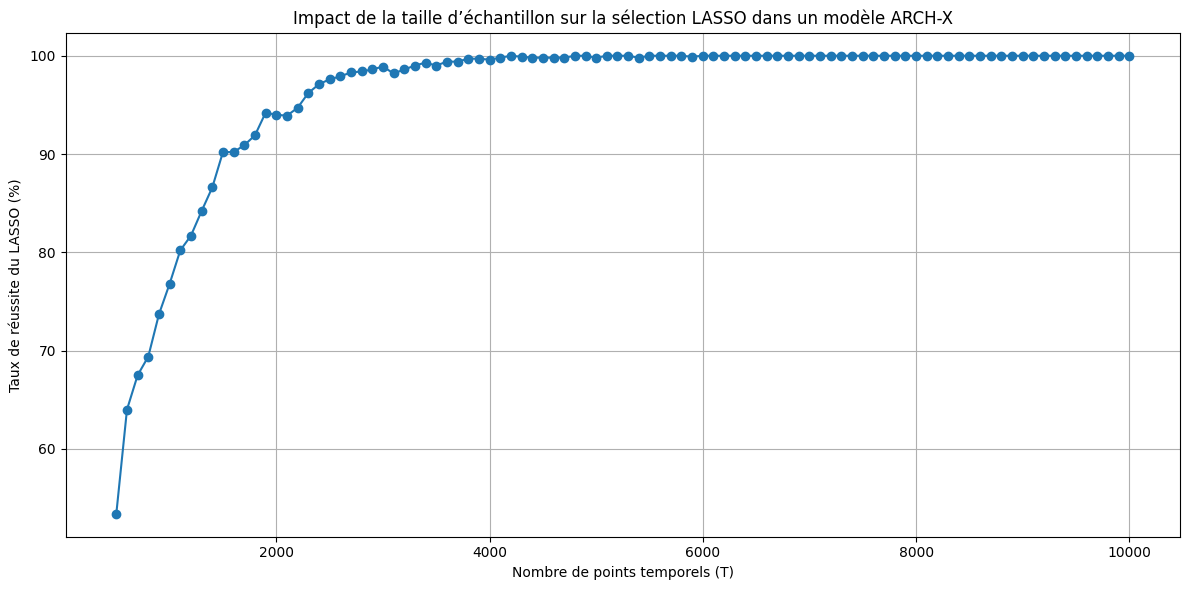

## 🧭 A faire
### ✅ Deux options valides pour passer à MS-ARCH-X

#### **Option 1: Initialisation via `get_initial_conditions` (recommandée)**

- Appeler `get_initial_conditions(eps, initial_params, d=2, q=1)`
- Passer les variables exogènes (additive ou transition)
- Permet d’estimer une version simplifiée du modèle (MS-ARCH-X ou MS-ARCH sans X) pour en déduire des bons paramètres de départ.

✅ Avantages :
- Théoriquement fondé
- Flexible
- Compatible avec la fonction `calibrate_and_store`

---

#### **Option 2: MS-ARCH simple + zéro-padding des exogènes**

- Estimer un MS-ARCH sans exogènes.
- Copier les paramètres estimés et ajouter des coefficients exogènes initialisés à 0.
- Utiliser ce vecteur comme point de départ pour une estimation complète MS-ARCH-X.

✅ Avantages :
- Simple, rapide, sans biais de sélection
- Permet de garder les propriétés théoriques du modèle

---

## 🛠️ Prochaine étape

➡️ Implémenter proprement l’appel à `get_initial_conditions` avec des données simulées (ou réelles), en spécifiant les champs nécessaires :
- `'exogen_additive'` pour la vol
- `'exogen_transition'` pour la matrice de transition

Et lancer une première estimation EM avec MS-ARCH-X complet sans effectuer de sélection stricte. On peut utiliser des exogènes AR(1), attention au nombre d'exo, et peut être commencer avec des exo que transitives / additives.
